In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Download the dataset
dataset_path = kagglehub.dataset_download("sudalairajkumar/covid19-in-india")

# Load the CSV file
file_path = os.path.join(dataset_path, "covid_19_india.csv")
df = pd.read_csv(file_path)

# Preview the data
df.head()

Using Colab cache for faster access to the 'covid19-in-india' dataset.


,Sno,Date,Time,State/UnionTerritory,ConfirmedIndianNational,ConfirmedForeignNational,Cured,Deaths,Confirmed
0,1,2020-01-30,6:00 PM,Kerala,1,0,0,0,1
1,2,2020-01-31,6:00 PM,Kerala,1,0,0,0,1
2,3,2020-02-01,6:00 PM,Kerala,2,0,0,0,2
3,4,2020-02-02,6:00 PM,Kerala,3,0,0,0,3
4,5,2020-02-03,6:00 PM,Kerala,3,0,0,0,3


In [3]:
print("Dataset Shape (rows, columns):", df.shape)
print("\nColumns in Dataset:")
print(df.columns.tolist())

Dataset Shape (rows, columns): (18110, 9)

Columns in Dataset:
['Sno', 'Date', 'Time', 'State/UnionTerritory', 'ConfirmedIndianNational', 'ConfirmedForeignNational', 'Cured', 'Deaths', 'Confirmed']


In [4]:
# Check column types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18110 entries, 0 to 18109
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Sno                       18110 non-null  int64 
 1   Date                      18110 non-null  object
 2   Time                      18110 non-null  object
 3   State/UnionTerritory      18110 non-null  object
 4   ConfirmedIndianNational   18110 non-null  object
 5   ConfirmedForeignNational  18110 non-null  object
 6   Cured                     18110 non-null  int64 
 7   Deaths                    18110 non-null  int64 
 8   Confirmed                 18110 non-null  int64 
dtypes: int64(4), object(5)
memory usage: 1.2+ MB


In [5]:
# Summary statistics
df.describe()

,Sno,Cured,Deaths,Confirmed
count,18110.000000,1.811000e+04,18110.000000,1.811000e+04
mean,9055.500000,2.786375e+05,4052.402264,3.010314e+05
std,5228.051023,6.148909e+05,10919.076411,6.561489e+05
min,1.000000,0.000000e+00,0.000000,0.000000e+00
25%,4528.250000,3.360250e+03,32.000000,4.376750e+03
50%,9055.500000,3.336400e+04,588.000000,3.977350e+04
75%,13582.750000,2.788698e+05,3643.750000,3.001498e+05
max,18110.000000,6.159676e+06,134201.000000,6.363442e+06


In [6]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Sno                         0
Date                        0
Time                        0
State/UnionTerritory        0
ConfirmedIndianNational     0
ConfirmedForeignNational    0
Cured                       0
Deaths                      0
Confirmed                   0
dtype: int64

Duplicate rows: 0


In [7]:
# Convert dates
df["Date"] = pd.to_datetime(df["Date"])
print("Date range:", df["Date"].min().strftime("%Y-%m-%d"), "to", df["Date"].max().strftime("%Y-%m-%d"))

Date range: 2020-01-30 to 2021-08-11


In [8]:
# Fix state name variations
state_corrections = {
    "Bihar****": "Bihar",
    "Madhya Pradesh*": "Madhya Pradesh",
    "Himanchal Pradesh*": "Himachal Pradesh",
    "Karanataka": "Karnataka",
    "Maharashtra***": "Maharashtra",
    "Telengana": "Telangana",
    "Dadra and Nagar Haveli": "Dadra and Nagar Haveli and Daman and Diu",
    "Daman & Diu": "Dadra and Nagar Haveli and Daman and Diu"
}

df["State/UnionTerritory"] = df["State/UnionTerritory"].replace(state_corrections)

# Fill missing state names
df["State/UnionTerritory"] = df["State/UnionTerritory"].fillna("Unknown")

print("Unique states/UTs count:", df["State/UnionTerritory"].nunique())

Unique states/UTs count: 38


In [9]:
# Calculate active cases
df["Active"] = df["Confirmed"] - df["Cured"] - df["Deaths"]

# Preview calculated values
df[["Date", "State/UnionTerritory", "Confirmed", "Cured", "Deaths", "Active"]].sample(5, random_state=42)

,Date,State/UnionTerritory,Confirmed,Cured,Deaths,Active
7998,2020-11-03,Arunachal Pradesh,14998,13238,38,1722
4028,2020-07-12,Tamil Nadu,134226,85915,1898,46413
4454,2020-07-24,Sikkim,460,122,0,338
17152,2021-07-16,Jharkhand,346533,341077,5120,336
6740,2020-09-28,Bihar,178702,164987,888,12827


In [10]:
# Remove placeholder rows
valid_states_df = df[~df["State/UnionTerritory"].isin(["Cases being reassigned to states", "Unassigned"])]

# Get the latest record for each state
state_data = (
    valid_states_df.sort_values("Date")
    .groupby("State/UnionTerritory")
    .last()
    .reset_index()
)

# Keep required columns
state_data = state_data[["State/UnionTerritory", "Confirmed", "Cured", "Deaths", "Active"]]

# Calculate rates
state_data["Death_Rate"] = (state_data["Deaths"] / state_data["Confirmed"].replace(0, np.nan)) * 100
state_data["Recovery_Rate"] = (state_data["Cured"].replace(0, np.nan) / state_data["Confirmed"].replace(0, np.nan)) * 100

# Round rates
state_data["Death_Rate"] = state_data["Death_Rate"].round(2)
state_data["Recovery_Rate"] = state_data["Recovery_Rate"].round(2)

# Show the top 10 states
top_10_table = state_data.sort_values(by="Confirmed", ascending=False).head(10)
top_10_table

,State/UnionTerritory,Confirmed,Cured,Deaths,Active,Death_Rate,Recovery_Rate
20,Maharashtra,6363442,6159676,134201,69565,2.11,96.80
16,Kerala,3586693,3396184,18004,172505,0.50,94.69
15,Karnataka,2921049,2861499,36848,22702,1.26,97.96
30,Tamil Nadu,2579130,2524400,34367,20363,1.33,97.88
1,Andhra Pradesh,1985182,1952736,13564,18882,0.68,98.37
33,Uttar Pradesh,1708812,1685492,22775,545,1.33,98.64
35,West Bengal,1534999,1506532,18252,10215,1.19,98.15
8,Delhi,1436852,1411280,25068,504,1.74,98.22
6,Chhattisgarh,1003356,988189,13544,1623,1.35,98.49
25,Odisha,988997,972710,6565,9722,0.66,98.35


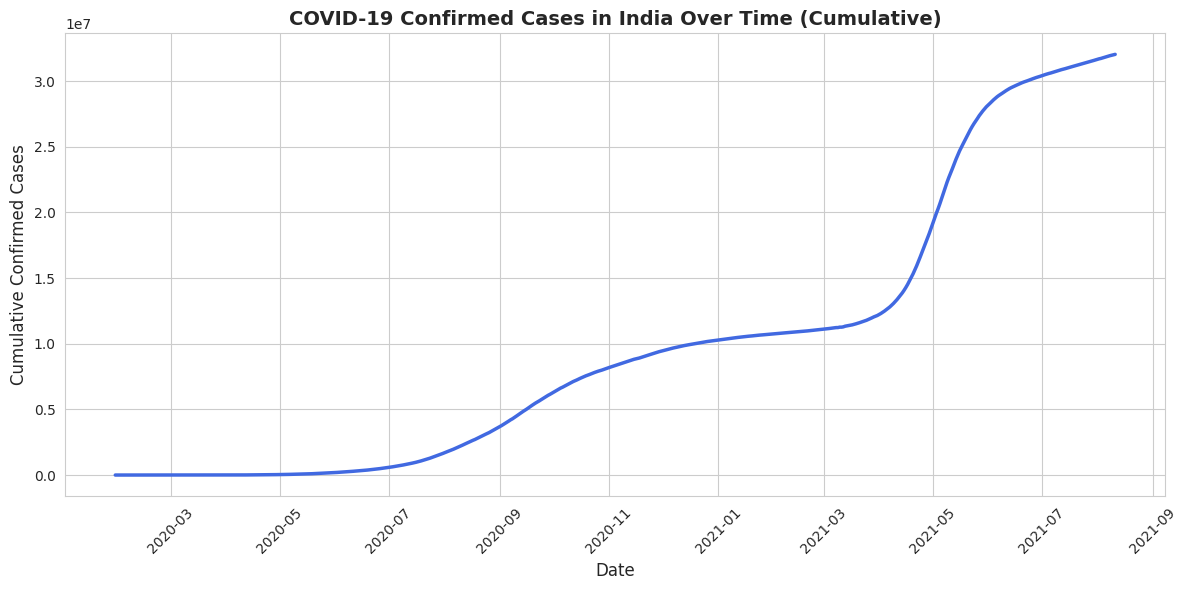

In [11]:
# Calculate national totals by date
national_cumulative = df.groupby("Date")["Confirmed"].sum()

plt.figure(figsize=(12, 6))
plt.plot(national_cumulative.index, national_cumulative.values, color="royalblue", linewidth=2.5)

plt.title("COVID-19 Confirmed Cases in India Over Time (Cumulative)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Cumulative Confirmed Cases", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

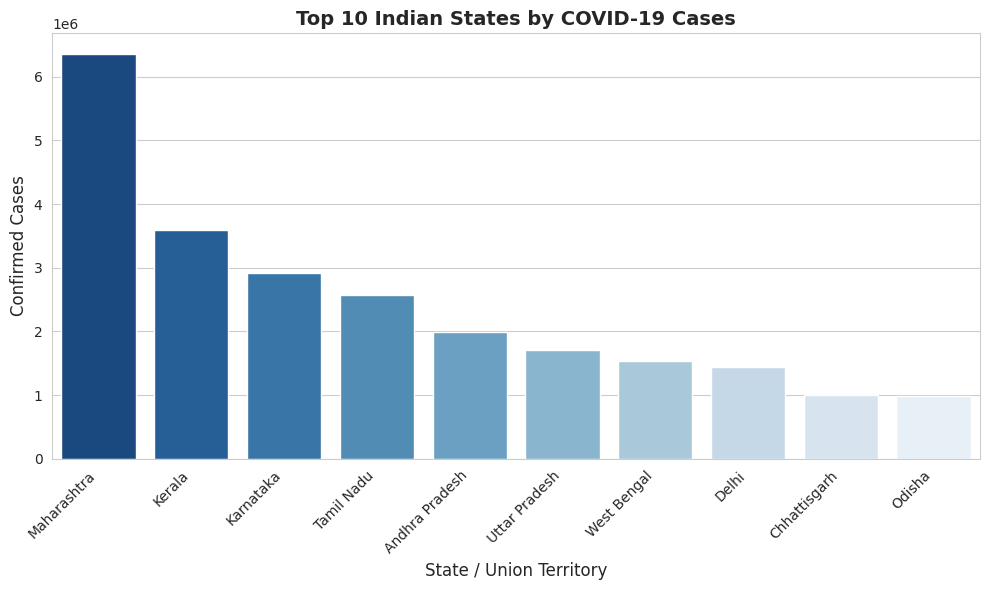

In [12]:
# Select the top 10 states
top_10_states = state_data.sort_values(by="Confirmed", ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_10_states,
    x="State/UnionTerritory",
    y="Confirmed",
    hue="State/UnionTerritory",
    palette="Blues_r",
    legend=False
)

plt.title("Top 10 Indian States by COVID-19 Cases", fontsize=14, fontweight="bold")
plt.xlabel("State / Union Territory", fontsize=12)
plt.ylabel("Confirmed Cases", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

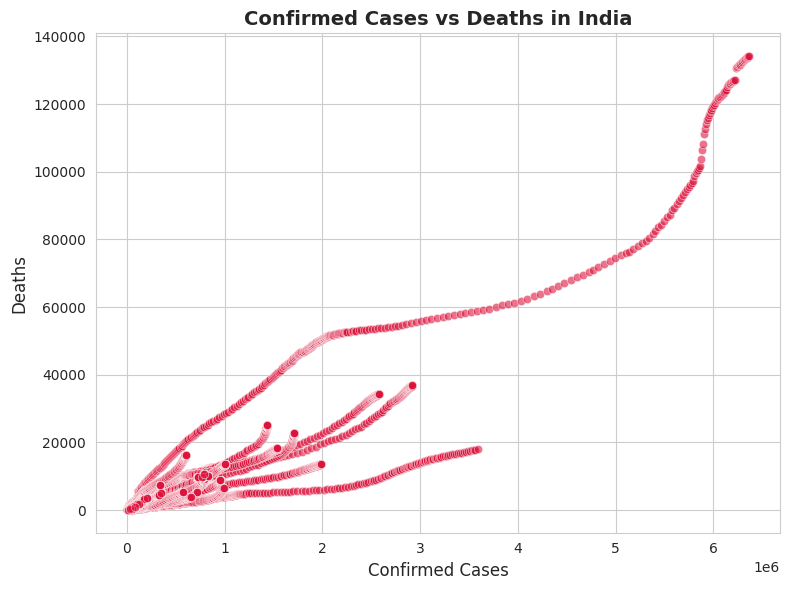

In [13]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=valid_states_df,
    x="Confirmed",
    y="Deaths",
    alpha=0.6,
    color="crimson"
)

plt.title("Confirmed Cases vs Deaths in India", fontsize=14, fontweight="bold")
plt.xlabel("Confirmed Cases", fontsize=12)
plt.ylabel("Deaths", fontsize=12)
plt.tight_layout()

plt.show()

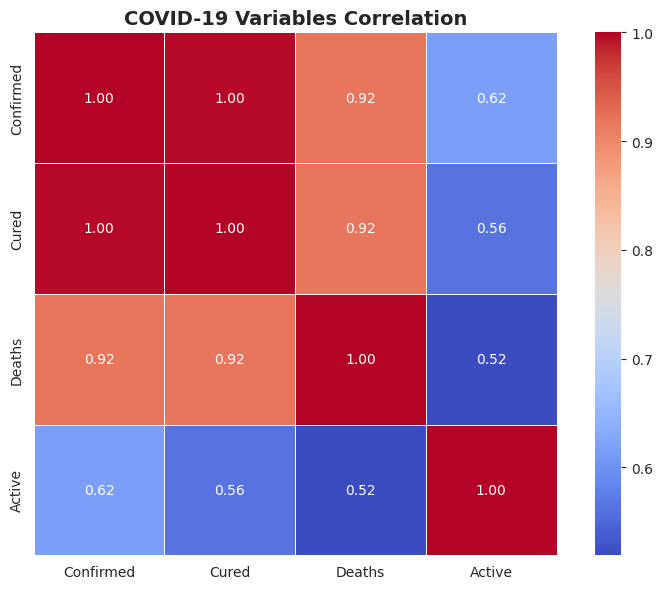

In [14]:
plt.figure(figsize=(8, 6))

# Select columns for correlation
covid_metrics = valid_states_df[["Confirmed", "Cured", "Deaths", "Active"]]
corr_matrix = covid_metrics.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.5
)

plt.title("COVID-19 Variables Correlation", fontsize=14, fontweight="bold")
plt.tight_layout()

plt.show()